# CIFAR-10 CNN versus FCNN (Master 1)

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 1 SIEC · 2023–2024  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare neural-network architectures on ten image categories.

**Approach:** Convolutional versus fully connected models, 2023–2024 coursework.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


<div class="alert alert-success">
    <center><b>University of Ghardaia</b></center>
    <center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 1 SIEC - 2023/2024</i></center>
</div>

------

<br><br>

<center>
    <span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Practical work 3 - AI: CIFAR-10 Deep Classification Without convolutional layers </span></span>
</center>
<br>
</center>

## Guerbouz Mohammed Alaa Eddine

### necessary import

In [2]:
from keras.datasets import cifar10
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
from keras.utils import to_categorical
import cv2  
import matplotlib.pyplot as plt

## Load CIFAR-10 dataset

In [3]:
# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

In [4]:
## The shape of X_Train
X_train.shape

(50000, 32, 32, 3)

In [5]:
## The shape of X_test
X_test.shape

(10000, 32, 32, 3)

In [6]:
## The shape of y_train
y_train.shape

(50000, 1)

In [7]:
## The reshape of y_train
y_train = y_train.reshape(-1,)
y_train[:5]

array([6, 9, 9, 4, 1], dtype=uint8)

In [8]:
y_test = y_test.reshape(-1,)

## Creatig array representing the classes we have

In [9]:
classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

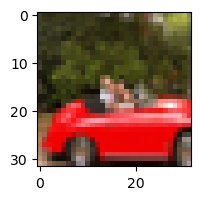

In [10]:
plt.figure(figsize=(15, 2))
plt.imshow(X_train[99])

## Normalize pixel values to be between 0 and 1

In [11]:

# Normalize pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


In [12]:
# One-hot encode target labels
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

## Flatten input data

In [15]:
X_train_flat = X_train.reshape((X_train.shape[0], -1))
X_test_flat = X_test.reshape((X_test.shape[0], -1))

## Build the FCnn modelto with its layers

In [16]:
model = Sequential()
model.add(Dense(512, activation='relu', input_shape=(X_train_flat.shape[1],)))
model.add(Dense(256, activation='relu'))
model.add(Dense(10, activation='softmax'))

## Compiling the FCnn model 

In [17]:
# Compile model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

## Train the model by fitting the X_train, y_train

In [21]:
# Train model
model.fit(X_train_flat, y_train, epochs=7)

Epoch 1/7
1563/1563 [==============================] - 23s 14ms/step - loss: 1.4137 - accuracy: 0.4953
Epoch 2/7
1563/1563 [==============================] - 22s 14ms/step - loss: 1.3711 - accuracy: 0.5108
Epoch 3/7
1563/1563 [==============================] - 20s 13ms/step - loss: 1.3478 - accuracy: 0.5208
Epoch 4/7
1563/1563 [==============================] - 20s 13ms/step - loss: 1.3296 - accuracy: 0.5248
Epoch 5/7
1563/1563 [==============================] - 21s 13ms/step - loss: 1.3098 - accuracy: 0.5317
Epoch 6/7
1563/1563 [==============================] - 22s 14ms/step - loss: 1.2909 - accuracy: 0.5383
Epoch 7/7
1563/1563 [==============================] - 21s 13ms/step - loss: 1.2796 - accuracy: 0.5437


## Evaluate model

In [22]:
# Evaluate model
loss, accuracy = model.evaluate(X_test_flat, y_test)
print(f'Test Loss: {loss}, Test Accuracy: {accuracy}')


313/313 [==============================] - 1s 2ms/step - loss: 1.4343 - accuracy: 0.4979
Test Loss: 1.4343479871749878, Test Accuracy: 0.49790000915527344


In [25]:
X_test_flat = X_test.reshape((X_test.shape[0], -1))

# Predict using the fully connected neural network model
y_pred = model.predict(X_test_flat)

# Print the first 5 predictions
print(y_pred[:5])

313/313 [==============================] - 1s 2ms/step
[[4.53238674e-02 3.25946920e-02 3.46302763e-02 3.72728348e-01
  1.73119649e-01 1.64784625e-01 2.91970950e-02 5.62838931e-03
  1.35754660e-01 6.23841258e-03]
 [5.97737869e-03 5.09711727e-03 2.10443977e-03 1.07152259e-03
  6.34298995e-05 1.13382375e-04 3.86762200e-04 1.33237324e-03
  7.53697157e-01 2.30156392e-01]
 [2.44921431e-01 1.85619798e-02 1.28019403e-03 4.26694111e-04
  5.91985357e-04 4.36671835e-04 1.08318609e-05 3.59732634e-03
  7.20397353e-01 9.77553520e-03]
 [1.86820656e-01 1.36898505e-02 1.75607577e-02 5.52684162e-03
  5.94626814e-02 2.86750635e-03 9.80717959e-05 1.44271672e-01
  5.63297689e-01 6.40435191e-03]
 [2.00848692e-04 7.07071649e-06 1.75468996e-02 2.00130939e-02
  6.59546554e-01 2.71072667e-02 2.73832887e-01 1.04207627e-03
  6.90264395e-04 1.29523096e-05]]


In [27]:
import numpy as np
prr = np.argmax(y_pred[1])
print(prr)
print(classes[prr])

8
ship


## import test image 

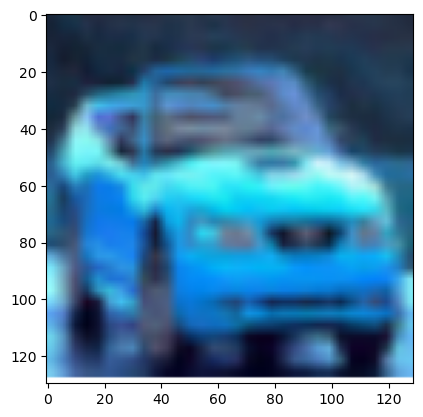

In [28]:
img = cv2.imread('testimg.png')
plt.imshow(img)


## Normalize pixels of this image

In [31]:
img = cv2.resize(img, (32, 32))

# Convert the image to array and normalize pixel values
img_array = img_to_array(img)
img_array = img_array / 255.0  # Normalize pixel values to [0, 1]

# Flatten the image to match the model's input shape
img_array_flat = img_array.reshape((1, 32 * 32 * 3))



## predict the image

In [32]:
predictions = model.predict(img_array_flat)

# Assuming you have defined the classes array earlier in your code
predicted_class_index = np.argmax(predictions)
predicted_class = classes[predicted_class_index]

1/1 [==============================] - 0s 13ms/step


In [34]:
print(np.argmax(predictions))

1


## import the origninal class and plot it , THe modele predicted the Image  

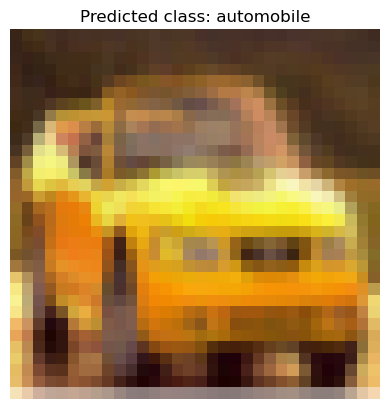

In [36]:
predicted_class = classes[np.argmax(predictions)]

# Display the image with the predicted class label
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Predicted class: " + predicted_class)
plt.axis('off')
plt.show()